# Fase 4: comparação de modelos

Escolhe, por validação cruzada temporal, o modelo que vai projetar a potência adicionada até 2030.

Entrada: `data/processed/aneel_serie_mensal_uf.parquet`. Modelos em [`src/modelos.py`](../src/modelos.py).
Referência: FPP3 §5.2 (naïve e drift), cap. 8 (ETS), cap. 9 (ARIMA), cap. 10 (regressão com erros ARIMA), §5.8–5.10
(métricas e validação cruzada), §13.4 (combinação de previsões); Bass (1969).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import estilo
import modelos as M
from estilo import CORES_UF, UFS

%matplotlib inline
estilo.aplicar()
warnings.simplefilter("ignore")
pd.set_option("display.precision", 3)

RES = ROOT / "resultados"
TODAS = UFS + ["SE"]
serie, y = M.carregar(ROOT / "data" / "processed" / "aneel_serie_mensal_uf.parquet")
print(f"{y['SE'].index[0]:%Y-%m} a {y['SE'].index[-1]:%Y-%m}")

2016-01 a 2026-06


## 1. Candidatos

Todos modelam o log da potência adicionada no mês. A previsão em MW é a média dos caminhos simulados já
retransformados, o que corrige o viés da retransformação do log (§5.6).

| modelo | o que supõe sobre o futuro |
|---|---|
| naïve | o último mês se repete (passeio aleatório) |
| drift | o crescimento médio de 2016–2026 continua |
| ETS(A,Ad,N) | nível e tendência que se atualizam, com tendência amortecida |
| ARIMA | ARIMA(p,1,q) com drift, ordens por AICc |
| intervenção (d=1) | modelo da fase 3: o crescimento do regime pós-corrida continua |
| tendência quebrada (d=0) | versão determinística do mesmo modelo (fase 3, seção 3) |
| Bass | difusão de Bass na potência acumulada: o mercado tem um potencial $m$ e satura |
| comb. ETS + Bass | média, caminho a caminho em MW, de ETS e Bass (§13.4) |
| comb. quebrada + Bass | média de tendência quebrada e Bass |

O Bass é ajustado por mínimos quadrados no log da potência adicionada no mês, que é
$m\,[F(t + \tau + 1) - F(t + \tau)]$, com $F(t) = \frac{1 - e^{-(p+q)t}}{1 + (q/p)\,e^{-(p+q)t}}$. O parâmetro $\tau$ desloca o início da
difusão, porque em 2016 a MMGD já existia. A incerteza vem de um AR(1) nos resíduos.

Nas combinações, os dois modelos recebem os mesmos choques em cada caminho. Assim o caminho combinado é a média de duas
leituras do mesmo futuro, e não uma mistura de dois futuros independentes.

## 2. Validação cruzada com origem móvel

Cada origem usa os dados até ela e prevê os 12 meses seguintes (§5.10). As origens vão de jun/2024 a jun/2025, uma por mês,
o que dá 13 janelas. A primeira origem precisa de pelo menos 12 meses depois da corrida, senão o modelo de intervenção não
consegue estimar o regime pós-corrida. A última precisa de 12 meses de teste dentro da série.

Métricas:
- **RMSE log**: erro da mediana prevista no log, ou seja, erro percentual aproximado (§5.8);
- **CRPS log**: qualidade da distribuição prevista inteira, calculada sobre os caminhos simulados (§5.9). Menor é melhor;
- **MAE MW**: erro absoluto médio da média prevista, em MW por mês;
- **viés e |erro| da soma de 12 meses**: erro na potência adicionada no ano seguinte, que é o que se acumula até 2030.
  Positivo quer dizer que o modelo previu menos que o observado;
- **cobertura 80% da soma**: fração das janelas em que a soma observada caiu no intervalo de 80%.

O cálculo leva alguns minutos, então o resultado fica guardado em `data/interim/cv_fase4.parquet`. Apague o arquivo para refazer.

In [2]:
ORIGENS = pd.date_range("2024-06-01", "2025-06-01", freq="MS")
H = 12
CACHE = ROOT / "data" / "interim" / "cv_fase4.parquet"
fabricas = M.candidatos()
if CACHE.exists():
    cv = pd.read_parquet(CACHE)
else:
    partes = []
    for uf in TODAS:
        c = M.validacao_cruzada(y[uf], fabricas, ORIGENS, h=H, n_sim=1000)
        partes.append(c.assign(uf=uf))
    cv = pd.concat(partes, ignore_index=True)
    cv.to_parquet(CACHE)
resumo = pd.concat({uf: M.resumo_cv(cv[cv.uf == uf]) for uf in TODAS})
resumo.loc["SE"].sort_values("CRPS log")

,RMSE log,CRPS log,MAE MW,viés soma 12m %,|erro| soma 12m %,cobertura 80% soma
modelo,,,,,,
comb. ETS + Bass,0.123,0.086,22.305,1.314,4.879,1.000
comb. quebrada + Bass,0.127,0.105,23.694,-1.761,4.513,1.000
naïve,0.216,0.163,96.470,-39.241,39.241,1.000
tendência quebrada (d=0),0.276,0.172,104.524,-42.677,42.677,1.000
"ETS(A,Ad,N)",0.316,0.179,88.323,-36.527,36.527,0.538
intervenção (d=1),0.377,0.207,125.617,-51.214,51.214,0.846
drift,0.587,0.318,263.420,-109.236,109.236,0.923
ARIMA,0.598,0.360,204.848,-85.079,85.079,0.000
Bass,0.612,0.429,94.861,39.156,39.156,0.000


In [3]:
# todas as UFs: CRPS e |erro| da soma de 12 meses
tab = resumo[["CRPS log", "|erro| soma 12m %"]].unstack(0).swaplevel(axis=1)
tab = tab.reindex(columns=pd.MultiIndex.from_product([TODAS, ["CRPS log", "|erro| soma 12m %"]]))
tab.round(3)

SP                         MG  \
                         CRPS log |erro| soma 12m % CRPS log   
modelo                                                         
naïve                       0.195            49.805    0.245   
drift                       0.390           134.866    0.328   
ETS(A,Ad,N)                 0.242            52.121    0.182   
ARIMA                       0.408           118.580    0.306   
intervenção (d=1)           0.335           103.914    0.266   
tendência quebrada (d=0)    0.290            85.262    0.255   
Bass                        0.267            26.480    0.679   
comb. ETS + Bass            0.118            14.026    0.189   
comb. quebrada + Bass       0.149            30.278    0.376   

                                                 RJ                    \
                         |erro| soma 12m % CRPS log |erro| soma 12m %   
modelo                                                                  
naïve                               70.752    0.222            55.070   
drift                              161.984    0.288           128.473   
ETS(A,Ad,N)                         26.975    0.148            21.360   
ARIMA                               68.673    0.271            64.688   
intervenção (d=1)                   22.927    0.183            39.341   
tendência quebrada (d=0)            22.277    0.198            43.087   
Bass                                53.785    0.539            47.037   
comb. ETS + Bass                    15.097    0.166            14.276   
comb. quebrada + Bass               35.494    0.179             7.851   

                               ES                         SE                    
                         CRPS log |erro| soma 12m % CRPS log |erro| soma 12m %  
modelo                                                                          
naïve                       0.302           165.740    0.163            39.241  
drift                       0.412           374.212    0.318           109.236  
ETS(A,Ad,N)                 0.213            47.396    0.179            36.527  
ARIMA                       0.429           119.863    0.360            85.079  
intervenção (d=1)           0.451           164.553    0.207            51.214  
tendência quebrada (d=0)    0.386           142.008    0.172            42.677  
Bass                        0.286            29.145    0.429            39.156  
comb. ETS + Bass            0.137            11.826    0.086             4.879  
comb. quebrada + Bass       0.213            56.431    0.105             4.513

In [4]:
# posição de cada modelo no CRPS por UF (1 = melhor)
ranking = resumo["CRPS log"].unstack(0)[TODAS].rank()
ranking["posição média"] = ranking.mean(axis=1)
ranking.sort_values("posição média").astype(float).round(1)

,SP,MG,RJ,ES,SE,posição média
modelo,,,,,,
comb. ETS + Bass,1.0,2.0,2.0,1.0,1.0,1.4
"ETS(A,Ad,N)",4.0,1.0,1.0,3.0,5.0,2.8
comb. quebrada + Bass,2.0,8.0,3.0,2.0,2.0,3.4
naïve,3.0,3.0,6.0,5.0,3.0,4.0
tendência quebrada (d=0),6.0,4.0,5.0,6.0,4.0,5.0
intervenção (d=1),7.0,5.0,4.0,9.0,6.0,6.2
Bass,5.0,9.0,9.0,4.0,9.0,7.2
drift,8.0,7.0,8.0,7.0,7.0,7.4
ARIMA,9.0,6.0,7.0,8.0,8.0,7.6


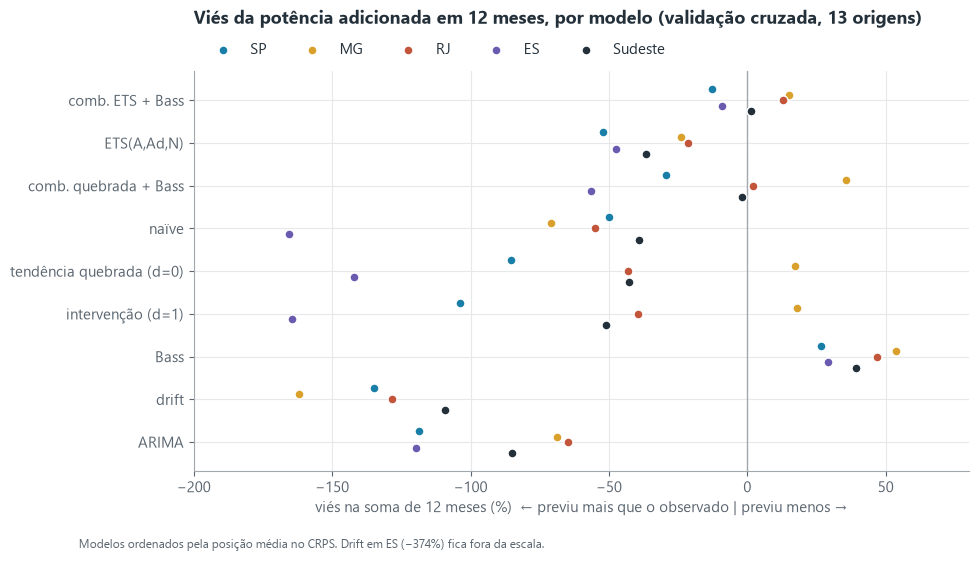

In [5]:
viés = resumo["viés soma 12m %"].unstack(0)[TODAS]
ordem = ranking.sort_values("posição média").index
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.axvline(0, color=estilo.NEUTRO, lw=1)
for k, uf in enumerate(TODAS):
    yy = np.arange(len(ordem)) + (k - 2) * 0.13
    ax.scatter(viés.loc[ordem, uf], yy, s=42, color=CORES_UF.get(uf, estilo.TINTA), label=uf if uf != "SE" else "Sudeste",
               edgecolor="white", linewidth=1, zorder=3)
ax.set_yticks(range(len(ordem)), ordem)
ax.invert_yaxis()
ax.set_xlabel("viés na soma de 12 meses (%)  ← previu mais que o observado | previu menos →")
ax.set_xlim(-200, 80)
ax.grid(axis="x", color=estilo.GRADE)
ax.legend(ncol=5, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Viés da potência adicionada em 12 meses, por modelo (validação cruzada, 13 origens)", pad=34)
estilo.fonte_rodape(fig, "Modelos ordenados pela posição média no CRPS. Drift em ES (−374%) fica fora da escala.")
fig.savefig(RES / "comparacao_vies.png")

LEITURA_CV

## 3. Exemplo: a origem de jun/2025

Previsões de 12 meses a partir de jun/2025 para o Sudeste, frente ao que aconteceu (jul/2025 a jun/2026).

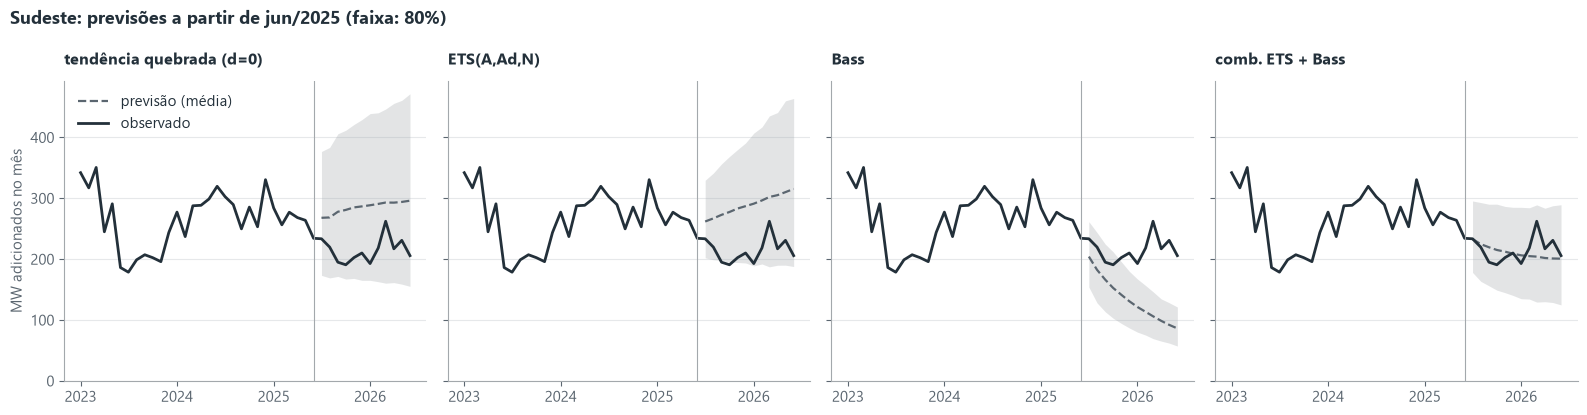

In [6]:
ORIG = pd.Timestamp("2025-06-01")
mostrar = ["tendência quebrada (d=0)", "ETS(A,Ad,N)", "Bass", "comb. ETS + Bass"]
z = np.random.default_rng(0).standard_normal((H, 2000))
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
obs = np.exp(y["SE"])
fut = M.futuro(y["SE"][:ORIG], H)
for ax, nome in zip(axes, mostrar):
    s = np.exp(fabricas[nome]().fit(y["SE"][:ORIG]).simulate(H, z, rng=np.random.default_rng(1)))
    ax.fill_between(fut, np.quantile(s, 0.1, axis=1), np.quantile(s, 0.9, axis=1), color=estilo.NEUTRO, alpha=0.3, lw=0)
    ax.plot(fut, s.mean(axis=1), color=estilo.TINTA_SUAVE, lw=1.6, ls="--", label="previsão (média)")
    ax.plot(obs["2023-01-01":].index, obs["2023-01-01":], color=estilo.TINTA, lw=2, label="observado")
    ax.axvline(ORIG, color=estilo.NEUTRO, lw=0.8)
    ax.set_title(nome, fontsize=11.5)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].set_ylabel("MW adicionados no mês")
axes[0].set_ylim(0, None)
axes[0].legend(loc="upper left")
fig.suptitle("Sudeste: previsões a partir de jun/2025 (faixa: 80%)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(RES / "comparacao_exemplo_se.png")

## 4. Os membros da combinação com a série inteira

Parâmetros do Bass ajustado até jun/2026 e diagnóstico do ETS. O $m$ do Bass é a potência acumulada final que a
difusão "enxerga" nos dados.

In [7]:
linhas = []
for uf in TODAS:
    b = M.Bass().fit(y[uf])
    e = M.ETS().fit(y[uf])
    acum = serie[serie.uf == uf]["mw_acumulado"].iloc[-1]
    lb = acorr_ljungbox(e.res.resid, lags=[24], model_df=4)["lb_pvalue"].iloc[0]
    linhas.append({"UF": uf, "Bass m (GW)": b.m / 1e3, "acumulado jun/26 (GW)": acum / 1e3,
                   "p (inovação)": b.p, "q (imitação)": b.q, "AR(1) resíduo": b.phi,
                   "ETS α": e.res.smoothing_level, "ETS β": e.res.smoothing_trend, "ETS φ": e.res.damping_trend,
                   "ETS Ljung-Box 24 p": lb})
membros = pd.DataFrame(linhas).set_index("UF")
membros

,Bass m (GW),acumulado jun/26 (GW),p (inovação),q (imitação),AR(1) resíduo,ETS α,ETS β,ETS φ,ETS Ljung-Box 24 p
UF,,,,,,,,,
SP,8.205,7.217,6.183e-05,0.077,0.729,0.603,6.032e-05,0.980,8.153e-02
MG,6.827,6.110,9.759e-05,0.072,0.636,0.321,3.207e-05,0.976,8.801e-02
RJ,2.312,1.997,8.873e-05,0.069,0.606,0.434,4.337e-05,0.980,3.716e-01
ES,1.536,1.328,4.998e-05,0.077,0.373,0.362,3.621e-05,0.980,3.141e-04
SE,19.139,16.652,7.857e-05,0.073,0.747,0.496,4.958e-05,0.980,3.280e-01


LEITURA_MEMBROS

## 5. Escolha

ESCOLHA